# Application du Perceptron : Breast Cancer Wisconsin

## Introduction

Après avoir construit et validé notre classe `Perceptron` sur des données factices, nous l'appliquons à un **problème réel de santé** : prédire si une tumeur du sein est **maligne** ou **bénigne** à partir de mesures faites sur des images de cellules.

**Objectifs**
1. Nettoyer et analyser les données avec rigueur (analyse exploratoire complète).
2. Réduire la dimensionnalité du tableau de données.
3. Modéliser avec notre Perceptron et l'évaluer avec des **métriques adaptées** à un contexte médical.
4. Conclure sur l'efficacité du Perceptron pour ce type de problème et proposer des solutions (sans les implémenter).

**Principes méthodologiques suivis dans tout le notebook**
- **Classe positive = tumeur maligne.** Le rappel (sensibilité) mesure donc la part des cancers détectés.
- **Pas de fuite de données** : le découpage train/test est fait avant tout apprentissage de transformation (standardisation, PCA, sélection de variables). Le jeu de test n'est utilisé qu'à la fin.
- **Reproductibilité** : graines aléatoires fixées.
- **Validation croisée sans fuite** : standardisation, réduction de dimensionnalité (et Boruta) sont réajustées à l'intérieur de chaque pli.

**Plan**
- 1. Les données
- 2. Nettoyage
- 3. Analyse exploratoire
- 4. Préparation (découpage et standardisation)
- 5. Réduction de dimensionnalité
- 6. Modélisation avec le Perceptron
- 7. Évaluation
- 8. Conclusion et solutions envisagées

---
# 1. Les données

Le jeu de données **Breast Cancer Wisconsin (Diagnostic)** décrit **569 patientes**. Pour chacune, des images numérisées d'une ponction à l'aiguille fine d'une masse mammaire ont servi à mesurer les noyaux cellulaires.

- **Cible** : `diagnosis` (M = maligne, B = bénigne).
- **10 mesures** par noyau cellulaire : rayon, texture, périmètre, aire, régularité (*smoothness*), compacité, concavité, points concaves, symétrie, dimension fractale.
- Chaque mesure est résumée par **3 statistiques**, ce qui donne **30 variables** : la moyenne (`_mean`), l'erreur standard (`_se`) et la « pire » valeur, c'est-à-dire la moyenne des trois plus grandes valeurs (`_worst`).

Ces variables sont donc issues d'un même ensemble de mesures : on s'attend à de fortes redondances (le rayon, le périmètre et l'aire décrivent la taille du noyau).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Perceptron as SkPerceptron
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

# Le dossier du dépôt (celui qui contient perceptron.py) doit être le dossier courant ou son parent.
import sys
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "perceptron.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("perceptron.py introuvable : lancez Jupyter depuis le dossier du dépôt.")
sys.path.insert(0, str(ROOT))

from perceptron import Perceptron   # notre classe (fichier perceptron.py)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

In [2]:
candidates = [ROOT / "bcw_data.csv", ROOT / "data" / "bcw_data.csv"]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Placez bcw_data.csv à la racine du dépôt ou dans un dossier data/.")

raw = pd.read_csv(DATA_PATH)
print("Fichier :", DATA_PATH, "| dimensions brutes :", raw.shape)
raw.head()

Fichier : /Users/mrstoure/Desktop/Etudes/Bachelor IT/B3 IA/Alternance/Building Perception/Draft1/data/bcw_data.csv | dimensions brutes : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


**Observation :** le fichier contient 569 lignes et 33 colonnes : un identifiant, la cible, 30 variables numériques, et une colonne `Unnamed: 32` qui n'est pas décrite dans la documentation. Cette colonne apparaît parce que chaque ligne du CSV se termine par une virgule en trop.

---
# 2. Nettoyage des données

In [3]:
print("--- Types des colonnes ---")
print(raw.dtypes.value_counts(), "\n")

print("--- Valeurs manquantes (colonnes concernées) ---")
missing = raw.isna().sum()
print(missing[missing > 0], "\n")

empty_cols = [c for c in raw.columns if raw[c].isna().all()]
print("Colonnes entièrement vides :", empty_cols)
print("Identifiants dupliqués     :", raw["id"].duplicated().sum())
print("Lignes dupliquées          :", raw.drop(columns=["id"]).duplicated().sum())
print("Modalités de 'diagnosis'   :", raw["diagnosis"].unique())

--- Types des colonnes ---
float64    31
int64       1
object      1
Name: count, dtype: int64 

--- Valeurs manquantes (colonnes concernées) ---
Unnamed: 32    569
dtype: int64 

Colonnes entièrement vides : ['Unnamed: 32']
Identifiants dupliqués     : 0
Lignes dupliquées          : 0
Modalités de 'diagnosis'   : ['M' 'B']


**Interprétation :**
- La colonne `Unnamed: 32` est **entièrement vide** (569 valeurs manquantes sur 569) : c'est un artefact du format du fichier, elle sera supprimée.
- **Aucune autre valeur manquante**, aucun identifiant dupliqué et aucune ligne dupliquée : pas d'imputation ni de dédoublonnage nécessaire.
- La cible ne comporte que deux modalités, `M` et `B`.

In [4]:
# Nettoyage : suppression de l'identifiant (sans valeur prédictive) et des colonnes vides,
# encodage de la cible (1 = maligne = classe positive, 0 = bénigne).
df = raw.drop(columns=["id"] + empty_cols).copy()
df["malignant"] = (df["diagnosis"] == "M").astype(int)
df = df.drop(columns="diagnosis")

X = df.drop(columns="malignant")
y = df["malignant"]
print("Variables :", X.shape[1], "| Observations :", X.shape[0])

# Contrôles de cohérence
print("\nValeurs négatives :", int((X < 0).sum().sum()))
zeros = (X == 0).sum()
print("Valeurs nulles par variable :")
print(zeros[zeros > 0])
print("\nRayon moyen vs périmètre/(2π) : écart relatif maximal =",
      round(float(((X["perimeter_mean"] / (2 * np.pi) - X["radius_mean"]).abs() / X["radius_mean"]).max()), 3))
print("Aire moyenne vs π·rayon² : écart relatif maximal       =",
      round(float(((np.pi * X["radius_mean"] ** 2 - X["area_mean"]).abs() / X["area_mean"]).max()), 3))

Variables : 30 | Observations : 569

Valeurs négatives : 0
Valeurs nulles par variable :
concavity_mean          13
concave points_mean     13
concavity_se            13
concave points_se       13
concavity_worst         13
concave points_worst    13
dtype: int64

Rayon moyen vs périmètre/(2π) : écart relatif maximal = 0.133
Aire moyenne vs π·rayon² : écart relatif maximal       = 0.091


**Interprétation :**
- L'**identifiant** n'a aucune valeur prédictive (c'est un numéro d'enregistrement) et pourrait même introduire un biais : il est supprimé.
- La cible est encodée en 0/1 avec **maligne = 1**, pour que le rappel mesure bien la détection des cancers.
- Aucune valeur négative. Les **valeurs nulles** (13 par colonne) ne concernent que les variables `concavity_*` et `concave points_*`, dans la même proportion pour les trois statistiques : ce sont des valeurs **réelles** (contours sans portion concave) et non des codes de valeurs manquantes. Nous les conservons.
- Les contrôles de cohérence géométrique (le rayon moyen est proche de périmètre/2π, l'aire de π·rayon²) montrent des écarts maximaux d'environ 13 % et 9 % : c'est normal, car le rayon est une moyenne de distances sur un contour qui n'est pas un cercle parfait. Aucune incohérence manifeste.

---
# 3. Analyse exploratoire

> L'analyse exploratoire est **descriptive** : elle ne sert à ajuster aucun modèle ni aucune transformation. Les transformations apprises (standardisation, PCA, sélection) seront calculées plus loin sur le jeu d'entraînement uniquement.

## 3.1 Équilibre des classes

malignant
Bénigne    357
Maligne    212
Name: count, dtype: int64 
 malignant
Bénigne    62.7 %
Maligne    37.3 %
Name: count, dtype: object


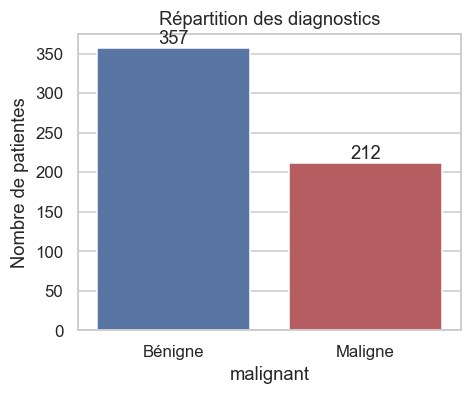

In [5]:
counts = y.value_counts().rename({0: "Bénigne", 1: "Maligne"})
print(counts, "\n", (counts / len(y) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=["#4c72b0", "#c44e52"], legend=False, ax=ax)
ax.set_ylabel("Nombre de patientes"); ax.set_title("Répartition des diagnostics")
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha="center")
plt.show()

**Interprétation :** 357 tumeurs bénignes (62,7 %) pour 212 malignes (37,3 %). Le déséquilibre est **modéré**. Un modèle qui prédirait « bénigne » pour tout le monde aurait déjà 63 % de précision : l'**accuracy seule est donc insuffisante** pour juger un modèle, et d'autant plus que les deux types d'erreur n'ont pas la même gravité (une tumeur maligne non détectée est bien plus grave qu'une fausse alerte). Nous nous appuierons sur le rappel, la précision, le F1-score et l'AUC. Nous utiliserons un découpage **stratifié** pour conserver les proportions de classes.

## 3.2 Statistiques descriptives et asymétrie

In [6]:
desc = X.describe().T[["mean", "std", "min", "50%", "max"]]
desc["skewness"] = X.apply(stats.skew)
desc.round(3).sort_values("skewness", ascending=False)

,mean,std,min,50%,max,skewness
area_se,40.337,45.491,6.802,24.530,542.200,5.433
concavity_se,0.032,0.030,0.000,0.026,0.396,5.097
fractal_dimension_se,0.004,0.003,0.001,0.003,0.030,3.914
perimeter_se,2.866,2.022,0.757,2.287,21.980,3.435
radius_se,0.405,0.277,0.112,0.324,2.873,3.080
smoothness_se,0.007,0.003,0.002,0.006,0.031,2.308
symmetry_se,0.021,0.008,0.008,0.019,0.079,2.189
compactness_se,0.025,0.018,0.002,0.020,0.135,1.897
area_worst,880.583,569.357,185.200,686.500,4254.000,1.854
fractal_dimension_worst,0.084,0.018,0.055,0.080,0.208,1.658


**Interprétation :** les variables ont des **échelles très différentes** : l'aire moyenne vaut en moyenne environ 655, alors que la dimension fractale vaut environ 0,06. Sans standardisation, les variables à grande échelle domineraient la somme pondérée du Perceptron. Plusieurs variables sont **fortement asymétriques** (skewness supérieure à 3 pour `area_se`, `concavity_se`, `fractal_dimension_se`, `perimeter_se`) avec de longues queues vers les grandes valeurs, ce qui annonce des valeurs atypiques.

## 3.3 Distributions selon le diagnostic

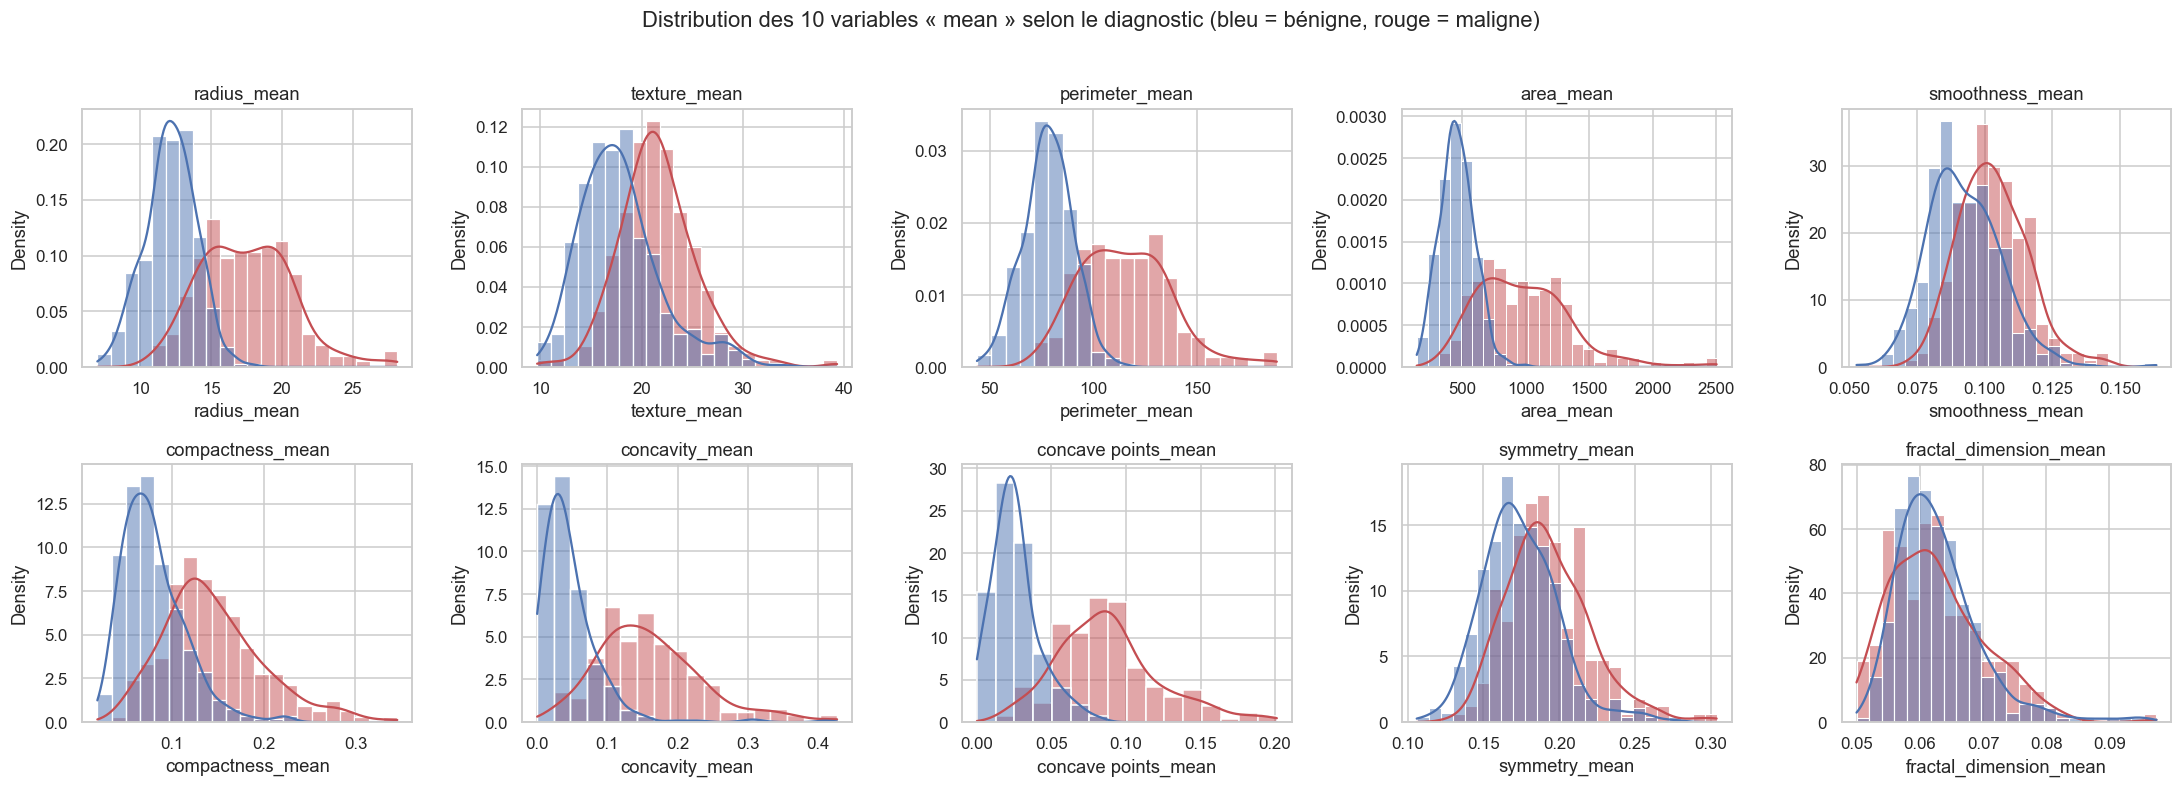

In [7]:
mean_cols = [c for c in X.columns if c.endswith("_mean")]
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), mean_cols):
    sns.histplot(data=df, x=col, hue="malignant", kde=True, stat="density", common_norm=False,
                 palette=["#4c72b0", "#c44e52"], ax=ax, legend=False)
    ax.set_title(col)
fig.suptitle("Distribution des 10 variables « mean » selon le diagnostic (bleu = bénigne, rouge = maligne)", y=1.02)
plt.tight_layout(); plt.show()

**Interprétation :** pour la plupart des mesures de taille et de forme (rayon, périmètre, aire, concavité, points concaves), la distribution des tumeurs malignes (rouge) est **décalée vers les grandes valeurs** par rapport aux bénignes (bleu), avec un chevauchement partiel. À l'inverse, `fractal_dimension_mean` se recouvre presque entièrement entre les deux classes (médianes quasi identiques) et `smoothness_mean` n'est que faiblement décalée : ces variables séparent mal les classes à elles seules.

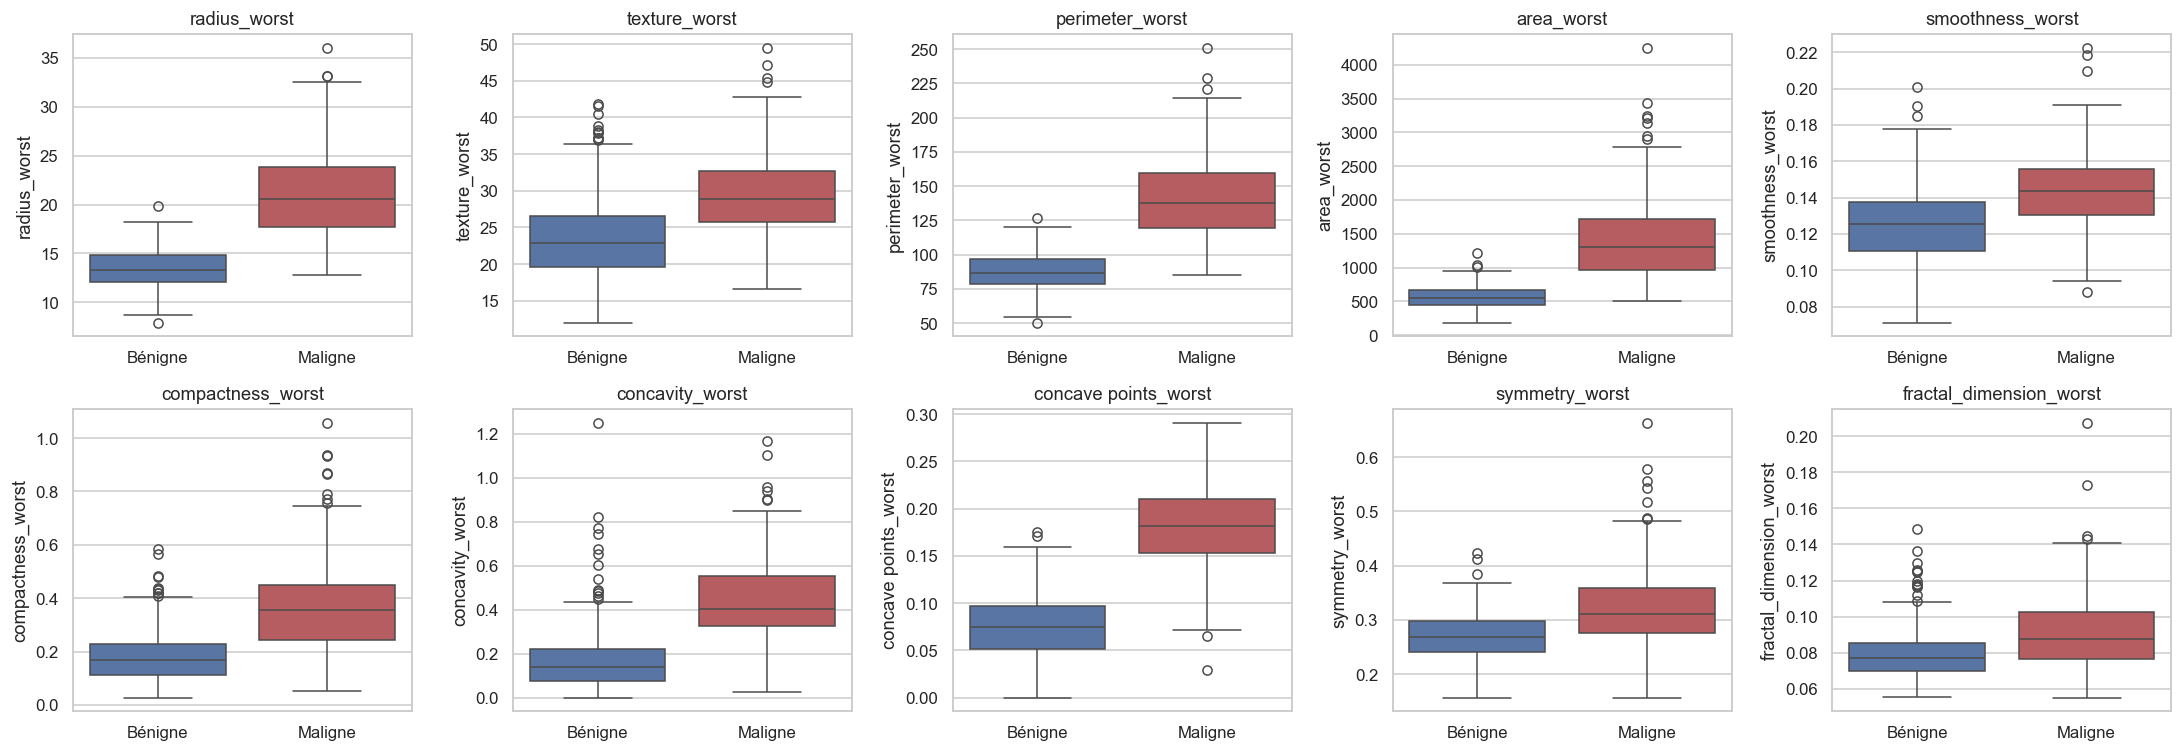

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), [c.replace("_mean", "_worst") for c in mean_cols]):
    sns.boxplot(data=df, x="malignant", y=col, hue="malignant", palette=["#4c72b0", "#c44e52"], legend=False, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Bénigne", "Maligne"]); ax.set_xlabel(""); ax.set_title(col)
plt.tight_layout(); plt.show()

**Interprétation :** sur les variables « worst », l'écart entre les médianes des deux classes est net pour les mesures de taille et de concavité, ce qui confirme leur pouvoir discriminant. Les tumeurs malignes présentent aussi une plus grande dispersion et davantage de valeurs extrêmes.

## 3.4 Valeurs atypiques

In [9]:
Q1, Q3 = X.quantile(0.25), X.quantile(0.75)
IQR = Q3 - Q1
is_out = (X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)

print("Variables avec le plus de valeurs atypiques (règle de l'IQR) :")
print(is_out.sum().sort_values(ascending=False).head(8), "\n")

row_has_out = is_out.any(axis=1)
print(f"Observations avec au moins une valeur atypique : {int(row_has_out.sum())} ({row_has_out.mean():.1%})")
print("Part de tumeurs malignes :")
print("  parmi les observations avec valeur atypique :", f"{y[row_has_out].mean():.1%}")
print("  parmi les autres                            :", f"{y[~row_has_out].mean():.1%}")

Variables avec le plus de valeurs atypiques (règle de l'IQR) :
area_se                 65
radius_se               38
perimeter_se            38
area_worst              35
smoothness_se           30
compactness_se          28
fractal_dimension_se    28
symmetry_se             27
dtype: int64 

Observations avec au moins une valeur atypique : 171 (30.1%)
Part de tumeurs malignes :
  parmi les observations avec valeur atypique : 66.7%
  parmi les autres                            : 24.6%


**Interprétation :** 171 observations (30 %) ont au moins une valeur atypique selon la règle de l'IQR, surtout sur les variables `_se` (erreurs standard) et `area_worst`. Parmi elles, **67 % sont des tumeurs malignes** contre 25 % parmi les autres : les valeurs atypiques sont en grande partie des **cas cliniques réels et informatifs** (grosses tumeurs), pas des erreurs de mesure. **Décision : nous ne les supprimons pas.** Les retirer éliminerait massivement des cas malins et appauvrirait le modèle. Leur effet sur le Perceptron sera atténué par la standardisation et la réduction de dimensionnalité, mais il reste une limite du modèle (sensibilité aux valeurs extrêmes).

## 3.5 Corrélations entre variables

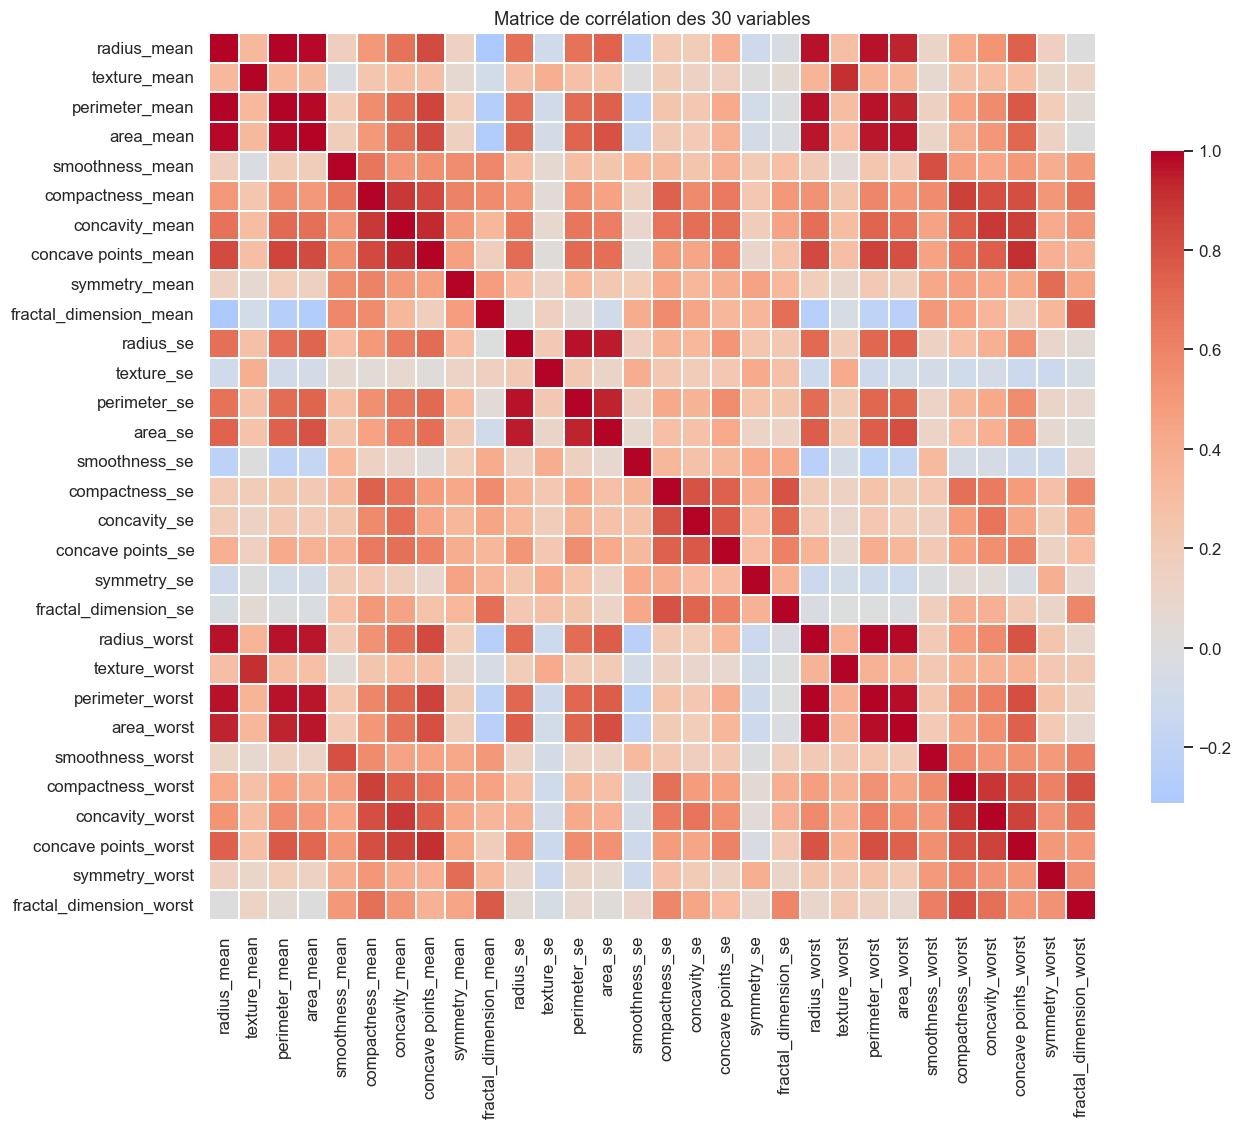

Paires de variables avec |corrélation| > 0,9 : 21
radius_mean      perimeter_mean     0.998
radius_worst     perimeter_worst    0.994
radius_mean      area_mean          0.987
perimeter_mean   area_mean          0.987
radius_worst     area_worst         0.984
perimeter_worst  area_worst         0.978
radius_se        perimeter_se       0.973
perimeter_mean   perimeter_worst    0.970
dtype: float64


In [10]:
corr = X.corr()
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, linewidths=0.2, cbar_kws={"shrink": 0.7})
plt.title("Matrice de corrélation des 30 variables")
plt.show()

upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print("Paires de variables avec |corrélation| > 0,9 :", int((pairs > 0.9).sum()))
print(pairs.head(8).round(3))

**Interprétation :** la matrice révèle de **grands blocs de variables très corrélées**. `radius`, `perimeter` et `area` sont quasiment colinéaires (jusqu'à 0,998 entre `radius_mean` et `perimeter_mean`), et on retrouve la même redondance entre les versions `mean` et `worst` d'une même mesure. On compte 21 paires avec une corrélation supérieure à 0,9. Cette **multicolinéarité** signifie que les 30 variables contiennent bien moins de 30 informations indépendantes, ce qui **justifie la réduction de dimensionnalité**. Pour le Perceptron, cela n'empêche pas le calcul mais rend les poids moins interprétables et l'apprentissage moins stable.

## 3.6 Lien avec le diagnostic

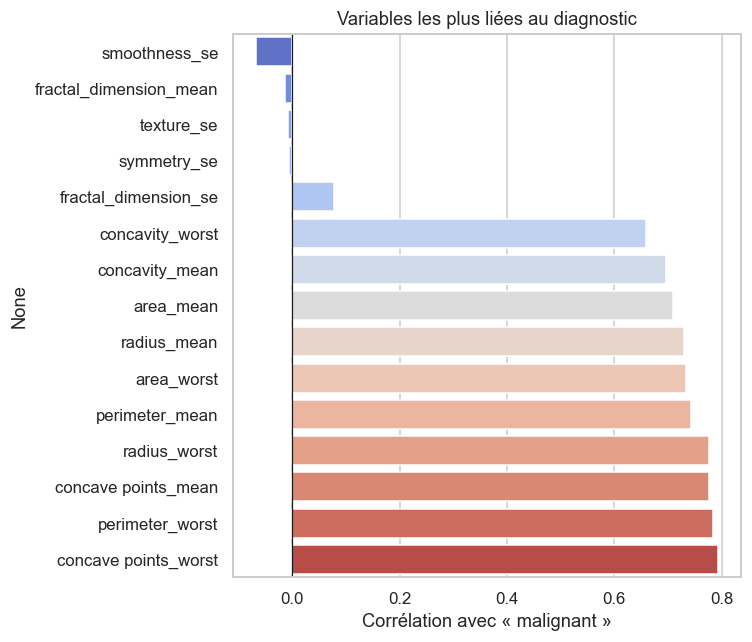

concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
dtype: float64


In [11]:
target_corr = X.corrwith(y).sort_values()
top = pd.concat([target_corr.head(5), target_corr.tail(10)])
plt.figure(figsize=(7, 6))
sns.barplot(x=top.values, y=top.index, hue=top.index, palette="coolwarm", legend=False)
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Corrélation avec « malignant »"); plt.title("Variables les plus liées au diagnostic")
plt.tight_layout(); plt.show()
print(target_corr.abs().sort_values(ascending=False).head(6).round(3))

**Interprétation :** les variables les plus liées à la malignité sont `concave points_worst` (0,79), `perimeter_worst` (0,78), `concave points_mean` (0,78) et `radius_worst` (0,78) : une tumeur maligne a des noyaux plus grands et au contour plus irrégulier (portions concaves). Quelques variables (`fractal_dimension_mean`, `texture_se`, `symmetry_se`) ont une corrélation quasi nulle avec la cible (inférieure à 0,02 en valeur absolue).

## 3.7 Vision multivariée : projection PCA en 2D

Variance expliquée par PC1 et PC2 : [0.443 0.19 ] | cumulée : 0.632


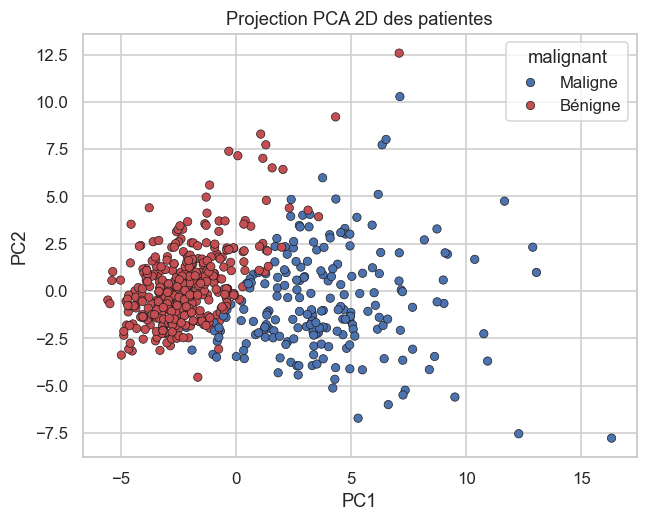

In [12]:
# Projection descriptive en 2D (PCA sur données standardisées). Aucune décision de modélisation n'en dépend.
Z = StandardScaler().fit_transform(X)
pca_vis = PCA(n_components=2).fit(Z)
Z2 = pca_vis.transform(Z)
print("Variance expliquée par PC1 et PC2 :", pca_vis.explained_variance_ratio_.round(3),
      "| cumulée :", pca_vis.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(6.5, 5))
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=y.map({0: "Bénigne", 1: "Maligne"}),
                palette=["#4c72b0", "#c44e52"], edgecolor="k", s=30)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Projection PCA 2D des patientes")
plt.show()

**Interprétation :** deux composantes seulement résument 63 % de la variance, et dans cette projection les deux classes forment **deux nuages largement distincts avec une zone de recouvrement**. C'est un bon signe pour un modèle linéaire, mais une projection en 2D ne permet pas de conclure : deux classes qui se chevauchent en 2D peuvent être parfaitement séparées dans l'espace complet à 30 dimensions, et inversement. **La séparabilité linéaire exacte sera donc testée rigoureusement à la section 7**, au lieu d'être déduite de ce graphique.

## 3.8 Tests statistiques

In [13]:
rows = []
for col in X.columns:
    u, p = stats.mannwhitneyu(X.loc[y == 1, col], X.loc[y == 0, col], alternative="two-sided")
    rows.append((col, p))
tests = pd.DataFrame(rows, columns=["variable", "p_value"]).sort_values("p_value")
alpha_bonf = 0.05 / len(X.columns)
print(f"Seuil de Bonferroni : {alpha_bonf:.4f}")
print("Variables significativement différentes entre les classes :", int((tests.p_value < alpha_bonf).sum()), "sur", len(tests))
tests.head(5).assign(p_value=lambda d: d.p_value.map("{:.2e}".format))

Seuil de Bonferroni : 0.0017
Variables significativement différentes entre les classes : 26 sur 30


,variable,p_value
22,perimeter_worst,2.58e-80
20,radius_worst,1.14e-78
23,area_worst,1.80e-78
27,concave points_worst,1.86e-77
7,concave points_mean,1.01e-76


**Interprétation :** un test de Mann-Whitney (sans hypothèse de normalité) compare chaque variable entre les deux classes. Après correction de Bonferroni (seuil 0,0017 pour 30 tests), **26 variables sur 30** diffèrent significativement entre tumeurs bénignes et malignes ; les plus discriminantes sont les variables de taille et de concavité « worst ». Cela confirme les observations graphiques.

**Conclusion de l'analyse exploratoire :**
- les classes sont bien distinctes (leur séparabilité linéaire exacte sera testée à la section 7), ce qui est favorable au Perceptron ;
- les variables sont à des échelles très différentes → **standardisation obligatoire** ;
- il existe une forte redondance entre variables → **réduction de dimensionnalité justifiée** ;
- les valeurs atypiques sont informatives → conservées ;
- le déséquilibre modéré et l'enjeu médical → **métriques centrées sur le rappel**.

---
# 4. Préparation : découpage et standardisation

On sépare d'abord les données en **80 % d'entraînement / 20 % de test** (stratifié), puis on standardise (moyenne 0, écart-type 1) en apprenant les paramètres **sur le train uniquement**, afin que le jeu de test reste réellement inconnu du modèle.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part de malignes — train :", f"{y_train.mean():.1%}", "| test :", f"{y_test.mean():.1%}")

# La standardisation apprend sa moyenne et son écart-type sur le train uniquement.
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

y_train_np, y_test_np = y_train.values, y_test.values
feature_sets = {"Toutes (30)": (X_train_s, X_test_s)}

Train : (455, 30) | Test : (114, 30)
Part de malignes — train : 37.4% | test : 36.8%


**Interprétation :** 455 patientes pour l'entraînement et 114 pour le test, avec des proportions de tumeurs malignes quasiment identiques (37,4 % et 36,8 %) grâce à la stratification. **Attention à la taille du jeu de test** : avec 114 patientes (dont 42 tumeurs malignes), une seule erreur de plus ou de moins change l'accuracy d'environ 0,9 point. Il faudra en tenir compte pour interpréter les résultats.

---
# 5. Réduction de dimensionnalité

Nous comparons trois approches, plus la référence sans réduction (30 variables) :

| Méthode | Type | Principe |
|---|---|---|
| **PCA** | Extraction | Remplace les variables par des combinaisons linéaires non corrélées, ordonnées par variance expliquée |
| **Filtre de corrélation** | Sélection | Supprime les variables fortement corrélées à une autre (seuil 0,9) |
| **Boruta** | Sélection | Compare l'importance (forêt aléatoire) de chaque variable à celle de copies aléatoires ; ne garde que celles qui les dépassent significativement |

## 5.1 PCA

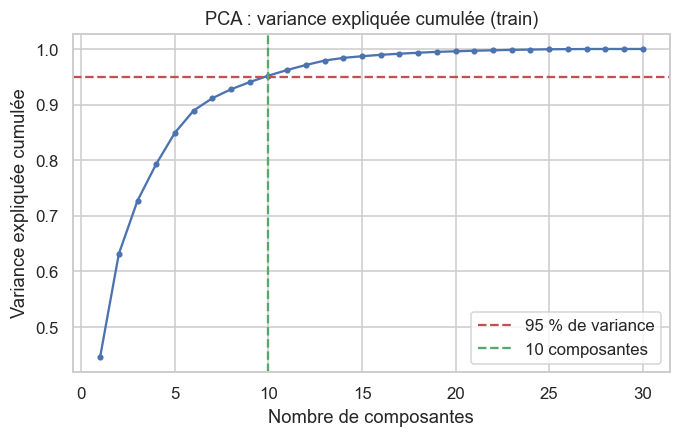

PCA : 30 variables -> 10 composantes
Variables qui pèsent le plus sur PC1 : ['concave points_mean', 'concavity_mean', 'concave points_worst', 'compactness_mean', 'perimeter_worst']


In [15]:
pca_full = PCA().fit(X_train_s)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum_var >= 0.95) + 1)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o", ms=3)
plt.axhline(0.95, color="r", ls="--", label="95 % de variance")
plt.axvline(n_comp, color="g", ls="--", label=f"{n_comp} composantes")
plt.xlabel("Nombre de composantes"); plt.ylabel("Variance expliquée cumulée"); plt.legend()
plt.title("PCA : variance expliquée cumulée (train)")
plt.show()

pca = PCA(n_components=n_comp).fit(X_train_s)
feature_sets["PCA (95 %)"] = (pca.transform(X_train_s), pca.transform(X_test_s))
print(f"PCA : {X_train_s.shape[1]} variables -> {n_comp} composantes")
loadings = pd.Series(pca.components_[0], index=X.columns).abs().sort_values(ascending=False)
print("Variables qui pèsent le plus sur PC1 :", list(loadings.head(5).index))

**Interprétation :** **10 composantes** suffisent pour conserver 95 % de la variance, au lieu de 30 variables. Les composantes sont non corrélées, ce qui supprime le problème de multicolinéarité. La première composante est portée par les variables de concavité, de points concaves et de taille : elle correspond à un axe « taille et irrégularité de la tumeur ». **Contrepartie** : les nouvelles variables sont moins directement interprétables que les mesures d'origine.

## 5.2 Filtre de corrélation

In [16]:
corr_train = pd.DataFrame(X_train_s, columns=X.columns).corr().abs()
upper_tr = corr_train.where(np.triu(np.ones(corr_train.shape), k=1).astype(bool))
to_drop = [c for c in upper_tr.columns if (upper_tr[c] > 0.9).any()]
kept = [c for c in X.columns if c not in to_drop]
idx_kept = [list(X.columns).index(c) for c in kept]

feature_sets["Filtre corrélation"] = (X_train_s[:, idx_kept], X_test_s[:, idx_kept])
print(f"Filtre de corrélation (seuil 0,9) : {len(X.columns)} -> {len(kept)} variables")
print("Supprimées :", to_drop)

Filtre de corrélation (seuil 0,9) : 30 -> 20 variables
Supprimées : ['perimeter_mean', 'area_mean', 'concave points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concave points_worst']


**Interprétation :** le filtre passe de 30 à **20 variables** en supprimant, parmi chaque groupe de variables redondantes, celles qui sont corrélées à une variable déjà présente (périmètres et aires redondants avec le rayon, versions `worst` redondantes, etc.). Il conserve les variables **d'origine**, donc interprétables, mais il se fonde uniquement sur les corrélations entre variables, sans regarder la cible.

## 5.3 Boruta

In [17]:
# Boruta (BorutaPy) : pip install Boruta
# Compatibilité : BorutaPy utilise parfois np.int / np.float / np.bool, retirés des versions récentes de NumPy.
try:
    for _name, _alias in [("int", int), ("float", float), ("bool", bool)]:
        if not hasattr(np, _name):
            setattr(np, _name, _alias)
    from boruta import BorutaPy
    BORUTA_OK = True
except ImportError:
    BORUTA_OK = False
    print("BorutaPy n'est pas installé : exécutez `pip install Boruta` puis relancez cette cellule.")

if BORUTA_OK:
    rf = RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=RANDOM_STATE)
    boruta = BorutaPy(rf, n_estimators="auto", max_iter=100, random_state=RANDOM_STATE)
    boruta.fit(X_train_s, y_train_np)                      # apprentissage sur le train uniquement
    selected = list(X.columns[boruta.support_])            # variables confirmées
    tentative = list(X.columns[boruta.support_weak_])      # variables indécises (non retenues)
    print(f"Boruta : {len(selected)} variables confirmées, {len(tentative)} indécises, "
          f"{X.shape[1] - len(selected) - len(tentative)} rejetées")
    print("Retenues :", selected)
    if len(selected) > 0:
        idx_b = [list(X.columns).index(c) for c in selected]
        feature_sets["Boruta"] = (X_train_s[:, idx_b], X_test_s[:, idx_b])

BorutaPy n'est pas installé : exécutez `pip install Boruta` puis relancez cette cellule.


**Interprétation :** Boruta est une méthode de sélection **supervisée** : elle garde les variables dont l'importance dans une forêt aléatoire est supérieure à celle de variables artificielles mélangées au hasard. Elle est ajustée sur le **train uniquement**. Le nombre de variables retenues s'affiche dans la sortie ci-dessus. **Remarque** : Boruta n'a pas pu être exécuté lors de la rédaction de ce notebook (bibliothèque non installable dans notre environnement) ; si vous l'installez (`pip install Boruta`), son jeu de variables s'ajoute automatiquement aux comparaisons ci-dessous. Commentez alors le nombre de variables retenues et comparez-les à celles du filtre de corrélation.

---
# 6. Modélisation avec le Perceptron

## 6.1 Choix des hyperparamètres par validation croisée

Pour chaque jeu de variables, on cherche le meilleur couple (taux d'apprentissage $\eta$, nombre d'époques) par **validation croisée stratifiée à 5 plis sur le train** (le test n'est pas utilisé). Le critère est le **F1-score** de la classe maligne, qui équilibre précision et rappel.

> **Validation croisée sans fuite de données.** À l'intérieur de chaque pli, la standardisation, la PCA, le filtre de corrélation (et Boruta, qui utilise les étiquettes) sont **réajustés uniquement sur les 4/5 d'entraînement** du pli, puis appliqués au 1/5 de validation. Rien n'est appris sur les observations de validation, et le jeu de test reste totalement intact.

La cellule `reducers` définit ces transformations, la cellule suivante lance la validation croisée (quelques minutes ; Boruta, s'il est installé, est ajusté une fois par pli).

In [18]:
def make_reducer(name, X_raw, y_):
    # Ajuste la standardisation ET la réduction sur (X_raw, y_) uniquement, et renvoie une fonction
    # transform(X_nouveau). On l'appelle sur chaque pli de la validation croisée : rien n'est appris
    # sur les observations de validation.
    sc = StandardScaler().fit(X_raw)
    Z = sc.transform(X_raw)
    if name == "Toutes (30)":
        return lambda A: sc.transform(A)
    if name == "PCA (95 %)":
        pca_ = PCA(n_components=0.95).fit(Z)
        return lambda A: pca_.transform(sc.transform(A))
    if name == "Filtre corrélation":
        upper_ = np.triu(pd.DataFrame(Z).corr().abs().values, k=1)
        keep_ = np.where(~(upper_ > 0.9).any(axis=0))[0]
        return lambda A: sc.transform(A)[:, keep_]
    if name == "Boruta":
        rf_ = RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=RANDOM_STATE)
        boruta_ = BorutaPy(rf_, n_estimators="auto", max_iter=100, random_state=RANDOM_STATE).fit(Z, y_)
        keep_ = np.where(boruta_.support_)[0]
        if len(keep_) == 0:
            keep_ = np.arange(Z.shape[1])
        return lambda A: sc.transform(A)[:, keep_]
    raise ValueError(name)


# Contrôle : appliquées à tout le train, ces fonctions redonnent exactement les jeux de variables de la section 5.
Xtr_raw = X_train.values
for name in feature_sets:
    if name != "Boruta":
        red = make_reducer(name, Xtr_raw, y_train_np)
        assert np.allclose(red(Xtr_raw), feature_sets[name][0]), name
print("Contrôle réussi : les fonctions de réduction reproduisent les jeux de variables de la section 5.")

Contrôle réussi : les fonctions de réduction reproduisent les jeux de variables de la section 5.


In [19]:
# Pour chaque pli, on réapprend standardisation + réduction (et Boruta le cas échéant) sur les 4/5 d'entraînement.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_data = {}
for name in feature_sets:
    folds = []
    for tr, va in skf.split(Xtr_raw, y_train_np):
        red = make_reducer(name, Xtr_raw[tr], y_train_np[tr])
        folds.append((red(Xtr_raw[tr]), y_train_np[tr], red(Xtr_raw[va]), y_train_np[va]))
    fold_data[name] = folds


def cross_validate_perceptron(folds, eta, n_epochs):
    # Renvoie (F1 moyen, écart-type du F1, rappel moyen) sur les plis.
    f1s, recalls = [], []
    for Xa, ya, Xb, yb in folds:
        m = Perceptron(learning_rate=eta, n_epochs=n_epochs, random_state=RANDOM_STATE).fit(Xa, ya)
        pred = m.predict(Xb)
        f1s.append(f1_score(yb, pred))
        recalls.append(recall_score(yb, pred))
    return np.mean(f1s), np.std(f1s), np.mean(recalls)


ETAS = [0.001, 0.01, 0.1, 1.0]
EPOCHS = [10, 50, 100, 300]

grids, best_params = {}, {}
for name in feature_sets:
    rows = []
    for eta in ETAS:
        for ep in EPOCHS:
            f1_m, f1_s, rec_m = cross_validate_perceptron(fold_data[name], eta, ep)
            rows.append(dict(eta=eta, n_epochs=ep, f1_cv=f1_m, f1_std=f1_s, recall_cv=rec_m))
    grids[name] = pd.DataFrame(rows)
    best_params[name] = grids[name].sort_values("f1_cv", ascending=False).iloc[0]

summary_cv = pd.DataFrame(best_params).T[["eta", "n_epochs", "f1_cv", "f1_std", "recall_cv"]]
summary_cv.round(3)

,eta,n_epochs,f1_cv,f1_std,recall_cv
Toutes (30),0.010,10.0,0.968,0.006,0.965
PCA (95 %),0.001,10.0,0.965,0.007,0.965
Filtre corrélation,0.100,10.0,0.962,0.014,0.959


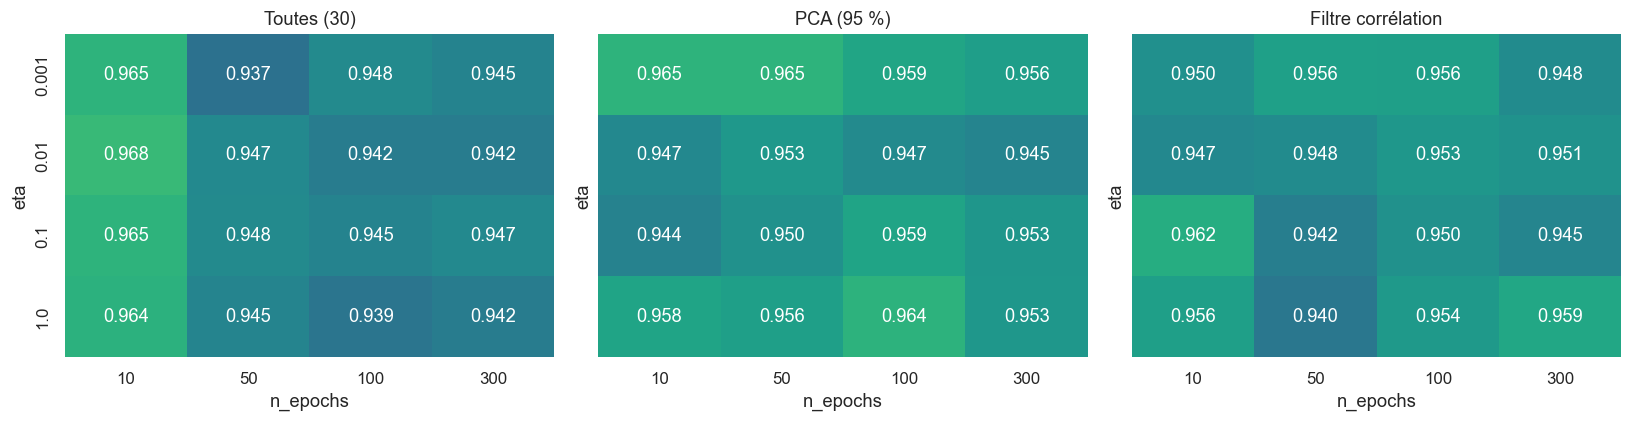

In [20]:
fig, axes = plt.subplots(1, len(grids), figsize=(5 * len(grids), 4), sharey=True)
for ax, (name, g) in zip(np.atleast_1d(axes), grids.items()):
    pivot = g.pivot(index="eta", columns="n_epochs", values="f1_cv")
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", cbar=False, ax=ax, vmin=0.9, vmax=1.0)
    ax.set_title(name)
plt.tight_layout(); plt.show()

**Interprétation :**
- Les F1 en validation croisée sont très proches : 0,968 (30 variables), 0,965 (PCA) et 0,962 (filtre de corrélation). Les écarts (0,003 à 0,006) sont **du même ordre que l'écart-type entre plis (0,006 à 0,014)** : aucune différence significative. En particulier, **réduire de 30 à 10 variables ne dégrade pas la performance**.
- **Nombre d'époques** : pour les 30 variables, le meilleur F1 est obtenu avec seulement **10 époques** (0,964 à 0,968) et il est plus bas avec 50 à 300 époques (0,937 à 0,948). Entraîner plus longtemps tend donc à **dégrader la généralisation** : le Perceptron s'acharne à classer correctement tous les exemples d'entraînement, y compris les plus ambigus. Un entraînement court joue le rôle d'un arrêt précoce. L'effet est moins net pour la PCA et le filtre.
- **Taux d'apprentissage** : peu d'influence. Comme les poids partent près de zéro, $\eta$ change surtout l'échelle des poids, pas la direction de l'hyperplan (comme vu sur les données factices).
- Conséquence : la sélection fine des hyperparamètres est **peu fiable** (elle suit en partie du bruit). Il faut lire ces résultats comme « le réglage ne compte pas beaucoup », pas comme « tel réglage est optimal ».

## 6.2 Choix du jeu de variables final (avant de regarder le test)

La règle est fixée ici, avant toute évaluation sur le jeu de test : on identifie le meilleur F1 moyen en validation croisée, puis on retient, parmi les jeux dont le F1 est **à moins d'un écart-type** de ce meilleur score, **le plus petit** (principe de parcimonie, dit « règle de l'écart-type »).

In [21]:
# Règle de sélection (fixée avant de regarder le jeu de test) : on repère le meilleur F1 moyen en validation croisée,
# puis, parmi les jeux dont le F1 est à moins d'un écart-type de ce meilleur score, on retient le plus petit
# (principe de parcimonie, dit « règle de l'écart-type »).
cv_f1 = summary_cv["f1_cv"].astype(float)
cv_std = summary_cv["f1_std"].astype(float)
best_name = cv_f1.idxmax()
eligible = [n for n in cv_f1.index if cv_f1[n] >= cv_f1[best_name] - cv_std[best_name]]
n_features = {n: feature_sets[n][0].shape[1] for n in feature_sets}
FINAL_SET = min(eligible, key=lambda n: n_features[n])
print(f"Meilleur F1 moyen en CV : {best_name} ({cv_f1[best_name]:.3f}, écart-type {cv_std[best_name]:.3f})")
print(f"Jeux à moins d'un écart-type du meilleur : {eligible}")
print(f"Jeu retenu (le plus petit parmi eux)     : {FINAL_SET} ({n_features[FINAL_SET]} variables)\n")

Meilleur F1 moyen en CV : Toutes (30) (0.968, écart-type 0.006)
Jeux à moins d'un écart-type du meilleur : ['Toutes (30)', 'PCA (95 %)', 'Filtre corrélation']
Jeu retenu (le plus petit parmi eux)     : PCA (95 %) (10 variables)



**Interprétation :** le meilleur F1 moyen revient aux 30 variables, mais les trois jeux sont dans la même marge d'un écart-type. La règle retient donc le plus petit, **la PCA à 10 composantes**. Ce choix est un choix de **parcimonie** et non une supériorité de performance : retenir les 30 variables aurait été tout aussi défendable. Nous l'assumons car le sujet demande de modéliser sur une table réduite et que la PCA supprime la multicolinéarité.

## 6.3 Comparaison sur le jeu de test

On entraîne chaque configuration retenue sur tout le train, puis on l'évalue sur le test. Comme le Perceptron s'arrête sur la **dernière** mise à jour (qui dépend du hasard dès que l'entraînement ne converge pas), on répète aussi l'entraînement avec **30 graines différentes** pour mesurer la stabilité, y compris pour l'AUC.

In [22]:
def evaluate(y_true, y_pred, scores=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    out = dict(accuracy=accuracy_score(y_true, y_pred),
               precision=precision_score(y_true, y_pred, zero_division=0),
               recall=recall_score(y_true, y_pred),
               specificity=float(tn / (tn + fp)),
               f1=f1_score(y_true, y_pred),
               FN=int(fn), FP=int(fp))
    if scores is not None:
        out["roc_auc"] = roc_auc_score(y_true, scores)
    return out


rows = []
for name, (Xtr_, Xte_) in feature_sets.items():
    p = best_params[name]
    m = Perceptron(learning_rate=p.eta, n_epochs=int(p.n_epochs), random_state=RANDOM_STATE).fit(Xtr_, y_train_np)
    res = evaluate(y_test_np, m.predict(Xte_), m.net_input(Xte_))
    # Stabilité : même réglage, 30 graines différentes (initialisation et ordre de mélange)
    accs, recs, aucs = [], [], []
    for seed in range(30):
        ms = Perceptron(learning_rate=p.eta, n_epochs=int(p.n_epochs), random_state=seed).fit(Xtr_, y_train_np)
        ps = ms.predict(Xte_)
        accs.append(accuracy_score(y_test_np, ps)); recs.append(recall_score(y_test_np, ps))
        aucs.append(roc_auc_score(y_test_np, ms.net_input(Xte_)))
    res.update(name=name, acc_mean_30=np.mean(accs), acc_std_30=np.std(accs), rec_mean_30=np.mean(recs),
               auc_mean_30=np.mean(aucs))
    rows.append(res)

comparison = pd.DataFrame(rows).set_index("name")[
    ["accuracy", "precision", "recall", "f1", "roc_auc", "FN", "FP", "acc_mean_30", "acc_std_30", "rec_mean_30", "auc_mean_30"]]
comparison.round(3)

,accuracy,precision,recall,f1,roc_auc,FN,FP,acc_mean_30,acc_std_30,rec_mean_30,auc_mean_30
name,,,,,,,,,,,
Toutes (30),0.921,0.884,0.905,0.894,0.972,4,5,0.961,0.014,0.938,0.989
PCA (95 %),0.974,0.976,0.952,0.964,0.997,2,1,0.958,0.023,0.941,0.992
Filtre corrélation,0.956,0.951,0.929,0.940,0.990,3,2,0.944,0.020,0.933,0.983


**Interprétation :**
- **Une seule graine est trompeuse.** Avec la graine 42, l'accuracy va de 0,921 (30 variables : 4 faux négatifs et 5 faux positifs) à 0,974 (PCA). En moyenne sur 30 graines, pourtant, les trois jeux sont proches : 0,961 (30 variables), 0,958 (PCA) et 0,944 (filtre), avec des écarts-types de 0,014 à 0,023. Le 0,921 des 30 variables vient d'un arrêt malchanceux de l'entraînement, pas d'un mauvais jeu de variables.
- **Portée de l'AUC.** La colonne `roc_auc` est l'AUC du modèle de graine 42 uniquement (0,972 / 0,997 / 0,990). La colonne `auc_mean_30` est la moyenne sur 30 graines (0,989 / 0,992 / 0,983) : c'est la seule représentative. Elle est très élevée : le score `net_input` classe très bien les patientes, même si le seuil de décision à zéro n'est pas parfait.
- Les différences entre jeux de variables restent dans le bruit de nos mesures. Le jeu retenu (PCA) a la meilleure AUC moyenne et une accuracy moyenne équivalente aux 30 variables.

---
# 7. Évaluation détaillée du modèle final

**Rappel du contexte médical.**
- Un **faux négatif** (tumeur maligne classée bénigne) est l'erreur la plus grave : elle retarde la prise en charge.
- Un **faux positif** (tumeur bénigne classée maligne) entraîne des examens complémentaires et du stress, mais il est moins dramatique.
- Les métriques clés sont donc le **rappel** (part des cancers détectés), la **précision** (part des alertes qui sont de vrais cancers), le **F1-score** (compromis), et l'**AUC** (qualité du classement indépendamment du seuil).

Jeu de variables : PCA (95 %) | eta = 0.001 | époques = 10
Convergence (zéro erreur sur le train) : False
Erreurs lors de la dernière époque     : 16 sur 455


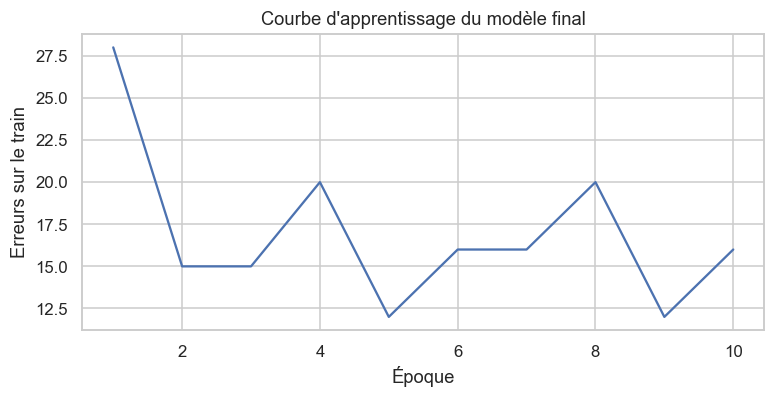

In [23]:
Xtr_f, Xte_f = feature_sets[FINAL_SET]
p = best_params[FINAL_SET]
print(f"Jeu de variables : {FINAL_SET} | eta = {p.eta} | époques = {int(p.n_epochs)}")

final_model = Perceptron(learning_rate=p.eta, n_epochs=int(p.n_epochs), random_state=RANDOM_STATE)
final_model.fit(Xtr_f, y_train_np)
y_pred = final_model.predict(Xte_f)
scores = final_model.net_input(Xte_f)

print("Convergence (zéro erreur sur le train) :", final_model.converged_)
print("Erreurs lors de la dernière époque     :", final_model.errors_[-1], "sur", len(y_train_np))

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, len(final_model.errors_) + 1), final_model.errors_)
plt.xlabel("Époque"); plt.ylabel("Erreurs sur le train"); plt.title("Courbe d'apprentissage du modèle final")
plt.show()

**Interprétation :** avec ce réglage (10 époques), l'entraînement s'arrête avec encore 16 erreurs sur 455 à la dernière époque. Pour ce jeu de 10 composantes, ce n'est pas qu'une question de durée d'entraînement : le test exact de la section suivante montre qu'aucun hyperplan ne sépare parfaitement ces données d'entraînement. Le modèle final dépend donc de l'endroit où l'entraînement s'arrête.

## 7.1 Les données sont-elles linéairement séparables ?

Ne pas converger dans une limite d'époques fixée **ne prouve pas** que les données ne sont pas linéairement séparables : le théorème de convergence garantit un arrêt en temps fini si elles le sont, mais ce temps peut être long. Nous le testons donc de façon **exacte** par programmation linéaire (existe-t-il un hyperplan qui classe correctement les 455 patientes d'entraînement ?), puis en laissant le Perceptron s'entraîner beaucoup plus longtemps.

In [24]:
from scipy.optimize import linprog

def is_linearly_separable(X_, y_):
    # Test exact de séparabilité linéaire stricte par programmation linéaire :
    # existe-t-il (w, b) avec y_i * (w.x_i + b) >= 1 pour tous les exemples ? (y_i recodé en -1/+1)
    s_ = 2 * y_ - 1
    A_ub = -(s_[:, None] * np.hstack([X_, np.ones((len(X_), 1))]))
    res = linprog(c=np.zeros(X_.shape[1] + 1), A_ub=A_ub, b_ub=-np.ones(len(X_)),
                  bounds=[(None, None)] * (X_.shape[1] + 1), method="highs")
    return res.status == 0          # 0 = solution trouvée ; 2 = système impossible

for name, (Xtr_, _) in feature_sets.items():
    print(f"{name:<20} -> train linéairement séparable : {is_linearly_separable(Xtr_, y_train_np)}")

# Le Perceptron converge-t-il si on lui laisse beaucoup plus d'époques sur les 30 variables ?
Xa_all, _ = feature_sets["Toutes (30)"]
long_run = Perceptron(learning_rate=0.01, n_epochs=3000, random_state=RANDOM_STATE).fit(Xa_all, y_train_np)
print(f"\nToutes (30), jusqu'à 3000 époques : converge = {long_run.converged_} (après {long_run.n_epochs_run_} époques)")

Toutes (30)          -> train linéairement séparable : True
PCA (95 %)           -> train linéairement séparable : False
Filtre corrélation   -> train linéairement séparable : True

Toutes (30), jusqu'à 3000 époques : converge = True (après 574 époques)


**Interprétation :**
- **30 variables standardisées : séparables.** Un hyperplan classe parfaitement les 455 patientes d'entraînement, et le Perceptron le trouve : il converge après 574 époques (η = 0,01, graine 42), alors qu'avec 300 époques il n'avait pas encore convergé. L'absence de convergence en 300 époques ne prouvait donc rien. Les 20 variables du filtre de corrélation sont aussi séparables (test exact).
- **PCA à 10 composantes : non séparables.** Ici l'absence de convergence est réelle (le test exact est négatif) : les 5 % de variance écartés suffisent à créer un recouvrement. C'est le cas du modèle final.
- **Séparer l'entraînement n'est pas bien généraliser.** Avec 30 variables et 455 exemples, séparer les données d'entraînement est relativement « facile » et ne garantit rien sur de nouvelles patientes : la validation croisée donne d'ailleurs un meilleur F1 avec 10 époques qu'avec 300. Le critère à retenir reste la performance sur des données non vues.

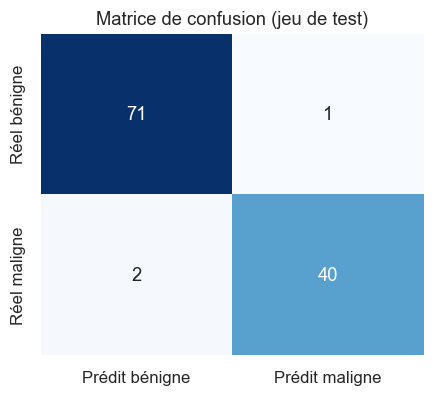

              precision    recall  f1-score   support

     bénigne      0.973     0.986     0.979        72
     maligne      0.976     0.952     0.964        42

    accuracy                          0.974       114
   macro avg      0.974     0.969     0.972       114
weighted avg      0.974     0.974     0.974       114

{'accuracy': 0.974, 'precision': 0.976, 'recall': 0.952, 'specificity': 0.986, 'f1': 0.964, 'FN': 2, 'FP': 1, 'roc_auc': np.float64(0.997)}


In [25]:
cm = confusion_matrix(y_test_np, y_pred)
plt.figure(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Prédit bénigne", "Prédit maligne"], yticklabels=["Réel bénigne", "Réel maligne"])
plt.title("Matrice de confusion (jeu de test)")
plt.show()

print(classification_report(y_test_np, y_pred, target_names=["bénigne", "maligne"], digits=3))
final_metrics = evaluate(y_test_np, y_pred, scores)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in final_metrics.items()})

**Interprétation (graine 42) :** sur les 114 patientes de test, le modèle commet **3 erreurs** : **2 faux négatifs** et **1 faux positif**. 40 des 42 tumeurs malignes sont détectées (rappel de 0,952), 40 des 41 alertes sont de vrais cancers (précision de 0,976) et 71 des 72 tumeurs bénignes sont bien reconnues (spécificité de 0,986). L'accuracy est de 0,974, le F1 de 0,964 et l'AUC de 0,997 (AUC de ce modèle précis ; la moyenne sur 30 graines est donnée plus bas).

**Mise en garde :** ce résultat est légèrement au-dessus de la moyenne sur 30 graines (accuracy de 0,958, voir plus bas). Il ne faut donc pas le présenter comme la performance « typique » du Perceptron.

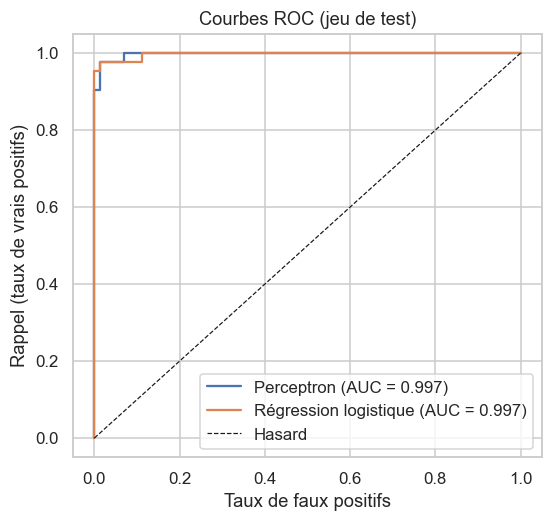

AUC Perceptron : 0.997 | AUC régression logistique : 0.997


In [26]:
lr = LogisticRegression(max_iter=1000).fit(Xtr_f, y_train_np)
lr_scores = lr.predict_proba(Xte_f)[:, 1]

fpr_p, tpr_p, _ = roc_curve(y_test_np, scores)
fpr_l, tpr_l, _ = roc_curve(y_test_np, lr_scores)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr_p, tpr_p, label=f"Perceptron (AUC = {roc_auc_score(y_test_np, scores):.3f})")
plt.plot(fpr_l, tpr_l, label=f"Régression logistique (AUC = {roc_auc_score(y_test_np, lr_scores):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="Hasard")
plt.xlabel("Taux de faux positifs"); plt.ylabel("Rappel (taux de vrais positifs)")
plt.title("Courbes ROC (jeu de test)"); plt.legend(loc="lower right")
plt.show()
print(f"AUC Perceptron : {roc_auc_score(y_test_np, scores):.3f} | AUC régression logistique : {roc_auc_score(y_test_np, lr_scores):.3f}")

**Interprétation :** les deux courbes ROC sont très proches du coin supérieur gauche, avec une AUC de 0,997 pour le Perceptron (graine 42) comme pour la régression logistique : à seuil variable, le score classe presque parfaitement les patientes. Attention : l'AUC du Perceptron indiquée ici est celle **d'un seul entraînement** ; sa moyenne sur 30 graines est donnée à la section suivante. Le Perceptron produit un score (`net_input`) mais **pas une probabilité** ; son seuil de décision est fixé à 0.

## 7.2 Stabilité du modèle selon la graine aléatoire

Accuracy sur 30 graines : moyenne 0.958 | écart-type 0.023 | min 0.904 | max 0.982
ROC-AUC sur 30 graines : moyenne 0.992 | min 0.973 | max 0.998
Faux négatifs (sur 42 tumeurs malignes) : moyenne 2.5 | min 1 | max 6


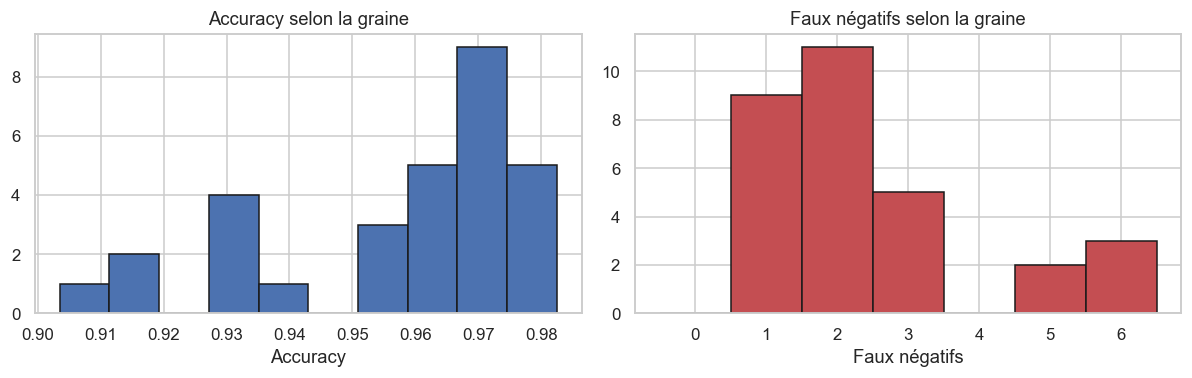

In [27]:
fn_counts, accs, aucs = [], [], []
for seed in range(30):
    m = Perceptron(learning_rate=p.eta, n_epochs=int(p.n_epochs), random_state=seed).fit(Xtr_f, y_train_np)
    ps = m.predict(Xte_f)
    accs.append(accuracy_score(y_test_np, ps))
    aucs.append(roc_auc_score(y_test_np, m.net_input(Xte_f)))
    fn_counts.append(int(((ps == 0) & (y_test_np == 1)).sum()))

print(f"Accuracy sur 30 graines : moyenne {np.mean(accs):.3f} | écart-type {np.std(accs):.3f} "
      f"| min {np.min(accs):.3f} | max {np.max(accs):.3f}")
print(f"ROC-AUC sur 30 graines : moyenne {np.mean(aucs):.3f} | min {np.min(aucs):.3f} | max {np.max(aucs):.3f}")
print(f"Faux négatifs (sur {int(y_test_np.sum())} tumeurs malignes) : moyenne {np.mean(fn_counts):.1f} "
      f"| min {min(fn_counts)} | max {max(fn_counts)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(accs, bins=10, color="#4c72b0", edgecolor="k"); axes[0].set_xlabel("Accuracy"); axes[0].set_title("Accuracy selon la graine")
axes[1].hist(fn_counts, bins=range(0, max(fn_counts) + 2), color="#c44e52", edgecolor="k", align="left")
axes[1].set_xlabel("Faux négatifs"); axes[1].set_title("Faux négatifs selon la graine")
plt.tight_layout(); plt.show()

**Interprétation :** à réglage identique, seules l'initialisation et l'ordre de mélange changent, et pourtant l'accuracy varie de **0,904 à 0,982** (moyenne 0,958, écart-type 0,023). L'AUC moyenne sur ces 30 graines est de **0,992** (de 0,973 à 0,998) : le classement des patientes par le score est stable et excellent, mais la décision prise au seuil 0 fluctue. Le nombre de **faux négatifs** va de **1 à 6** sur 42 tumeurs malignes (moyenne 2,5) : dans le pire cas, plus de 14 % des cancers ne sont pas détectés. C'est la principale faiblesse du Perceptron sur ce problème : il s'arrête sur son dernier jeu de poids et, avec 10 composantes, les données d'entraînement ne sont pas séparables, donc **le résultat est instable**. En contexte médical, cette variabilité serait inacceptable sans précaution.

## 7.3 Comparaison avec des références

In [28]:
baselines = {
    "Dummy (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=1000),
    "Perceptron scikit-learn": SkPerceptron(random_state=RANDOM_STATE),
}
rows = []
for name, mdl in baselines.items():
    mdl.fit(Xtr_f, y_train_np)
    rows.append({"modèle": name, **evaluate(y_test_np, mdl.predict(Xte_f))})
rows.append({"modèle": "Notre Perceptron (graine 42)", **evaluate(y_test_np, y_pred)})
pd.DataFrame(rows).set_index("modèle").round(3)

,accuracy,precision,recall,specificity,f1,FN,FP
modèle,,,,,,,
Dummy (classe majoritaire),0.632,0.000,0.000,1.000,0.000,42,0
Régression logistique,0.974,1.000,0.929,1.000,0.963,3,0
Perceptron scikit-learn,0.965,0.952,0.952,0.972,0.952,2,2
Notre Perceptron (graine 42),0.974,0.976,0.952,0.986,0.964,2,1


**Interprétation :**
- Le modèle **naïf** (toujours « bénigne ») atteint 63 % d'accuracy mais détecte **0 %** des cancers : il confirme que l'accuracy seule est trompeuse et que notre Perceptron apporte un vrai signal.
- La **régression logistique** (accuracy 0,974, 3 faux négatifs, 0 faux positif), le **Perceptron de scikit-learn** (0,965, 2 faux négatifs, 2 faux positifs) et le nôtre (0,974, 2 faux négatifs, 1 faux positif avec la graine 42) sont **équivalents** : l'écart n'est que d'une à deux patientes sur 114, ce qui est dans le bruit. Notre implémentation est cohérente avec la référence.
- Pour juger sérieusement une différence de performance, il faudrait **répéter** les découpages (validation croisée répétée) ou calculer des intervalles de confiance, au lieu de se fier à un seul jeu de test de 114 patientes.

---
# 8. Conclusion et solutions envisagées

## 8.1 Efficacité du Perceptron sur ce problème

**Points positifs**
- Le Perceptron est **efficace** : avec standardisation et réduction de dimensionnalité, il atteint en moyenne environ **96 % d'accuracy** (0,958 sur 30 graines) et une AUC moyenne de **0,992** sur le jeu de test, très au-dessus du modèle naïf (63 %), et à un niveau comparable à la régression logistique et au Perceptron de scikit-learn.
- Il est **simple et rapide** : 10 époques suffisent sur 455 exemples, et il est facile à expliquer.
- L'analyse exploratoire montrait des classes bien distinctes, et le test exact confirme qu'elles sont linéairement séparables sur le train avec les 30 variables : cela explique ce bon résultat.

**Limites constatées**
- **Convergence conditionnelle.** Avec 30 variables, le train est séparable mais le Perceptron met plusieurs centaines d'époques à converger (574) sans gain de généralisation ; avec la PCA à 10 composantes, le train n'est pas séparable et le Perceptron ne peut pas converger.
- **Instabilité** : selon la graine, l'accuracy varie de 0,90 à 0,98 et les faux négatifs de 1 à 6. Un seul entraînement ne permet pas de conclure.
- **Pas de probabilité ni de seuil réglable** : impossible de privilégier explicitement le rappel pour réduire les faux négatifs.
- **Sensibilité** à l'échelle des variables (standardisation indispensable), aux valeurs atypiques et à la multicolinéarité.
- **Données limitées** : 569 patientes et un test de 114, donc des estimations imprécises (une erreur = 0,9 point d'accuracy) et aucune validation externe.
- Les choix de réduction de dimensionnalité et d'hyperparamètres **ne se distinguent pas statistiquement** dans nos mesures.

**Verdict :** le Perceptron est un **bon point de départ** pour cette classification, mais **insuffisant seul pour un usage clinique** : il doit être vu comme un outil d'aide à la décision, jamais comme un diagnostic autonome.

## 8.2 Solutions proposées (non implémentées)

1. **Régression logistique** (sigmoïde, perte d'entropie croisée) : sortie probabiliste et **seuil de décision ajustable** pour minimiser les faux négatifs, avec un entraînement plus stable (problème convexe).
2. **Stabiliser le Perceptron** : conserver les meilleurs poids rencontrés (algorithme *pocket*), moyenner les poids au fil de l'entraînement (*averaged perceptron*), faire décroître le taux d'apprentissage.
3. **Perceptron multicouche (MLP)** : couches cachées et activations non linéaires (ReLU), entraînées par rétropropagation, pour modéliser des frontières non linéaires dans la zone de recouvrement.
4. **Modèles plus robustes sur données tabulaires** : SVM à noyau (marge maximale), forêts aléatoires, gradient boosting.
5. **Évaluation plus fiable** : validation croisée répétée, intervalles de confiance (bootstrap), moyenne sur plusieurs graines, test sur une cohorte externe.
6. **Régularisation** (L1/L2) et **sélection de variables** intégrée pour limiter le surapprentissage.
7. **Optimisation du seuil et des coûts** : pondération des classes ou choix du seuil sur la courbe ROC en fonction du coût médical d'un faux négatif.
8. **Explicabilité** (importance des variables, SHAP) pour justifier les décisions auprès des cliniciens.
9. **Plus de données et validation clinique** avant tout usage réel.